## 04 Churn Prediction

**Objective:** Predict whether a player who is currently active will stop playing during the following 14 days.

For a player active on a snapshot date:
- Features use behaviour from the previous 14 days, including the snapshot date.
- `churn = 1` if the player has no activity during the next 14 days.
- `churn = 0` if the player returns at least once during the next 14 days.

A time-based train/test split is used to avoid future-data leakage and better represent deployment.

In [3]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.db import get_connection

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

conn = get_connection()

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

print("Database connected")

Database connected


In [4]:

player_day = pd.read_sql_query("""
SELECT
    device_id,
    activity_date,
    player_level,
    session_count,
    playtime_minutes
FROM player_day
""", conn)

player_day['date'] = pd.to_datetime(
    player_day['activity_date'].astype(str),
    format='%Y%m%d'
)


activity = pd.read_sql_query("""
SELECT
    device_id,
    activity_date
FROM player_day

UNION

SELECT
    device_id,
    CAST(strftime('%Y%m%d', event_ts) AS INTEGER) AS activity_date
FROM purchase
""", conn)

activity['date'] = pd.to_datetime(
    activity['activity_date'].astype(str),
    format='%Y%m%d'
)


print("Player-day rows:", len(player_day))
print(
    "Player-day date range:",
    player_day['date'].min(),
    "to",
    player_day['date'].max()
)

print("\nUnified activity rows:", len(activity))
print(
    "Unified activity date range:",
    activity['date'].min(),
    "to",
    activity['date'].max()
)

display(player_day.head())

Player-day rows: 667435
Player-day date range: 2026-01-01 00:00:00 to 2026-04-30 00:00:00

Unified activity rows: 670046
Unified activity date range: 2026-01-01 00:00:00 to 2026-04-30 00:00:00


,device_id,activity_date,player_level,session_count,playtime_minutes,date
0,100029,20260101,19,5,3.9000,2026-01-01
1,100136,20260101,19,3,9.3000,2026-01-01
2,100154,20260101,3,4,12.2000,2026-01-01
3,100156,20260101,12,1,41.7000,2026-01-01
4,100260,20260101,16,3,38.1000,2026-01-01


In [ ]:
def build_snapshot(snapshot_date, player_day, activity):

    snapshot_date = pd.Timestamp(snapshot_date)

   
    active_today = activity[
        activity['date'] == snapshot_date
    ][['device_id']].drop_duplicates()

   
    feature_start = (
        snapshot_date - pd.Timedelta(days=13)
    )

    history = player_day[
        (player_day['date'] >= feature_start) &
        (player_day['date'] <= snapshot_date)
    ].copy()

    features = (
        history
        .groupby('device_id')
        .agg(
            active_days_14d=('date', 'nunique'),
            sessions_14d=('session_count', 'sum'),
            playtime_14d=('playtime_minutes', 'sum'),
            avg_playtime_active_day=('playtime_minutes', 'mean'),
            avg_sessions_active_day=('session_count', 'mean'),
            current_level=('player_level', 'max')
        )
        .reset_index()
    )

  
    label_start = (
        snapshot_date + pd.Timedelta(days=1)
    )

    label_end = (
        snapshot_date + pd.Timedelta(days=14)
    )

    future = activity[
        (activity['date'] >= label_start) &
        (activity['date'] <= label_end)
    ]

    future_active = set(
        future['device_id'].unique()
    )

    df = active_today.merge(
        features,
        on='device_id',
        how='left'
    )

    df['churn'] = (
        ~df['device_id'].isin(future_active)
    ).astype(int)

    df['snapshot_date'] = snapshot_date

    return df

In [6]:
snapshot_dates = [
    '2026-02-15',
    '2026-03-01',
    '2026-03-15',
    '2026-04-01',
    '2026-04-16'
]

snapshot_frames = []

for date in snapshot_dates:

    temp = build_snapshot(
        date,
        player_day,
        activity
    )

    print(
        date,
        "| players:", len(temp),
        "| churn rate:",
        round(temp['churn'].mean(), 4)
    )

    snapshot_frames.append(temp)

model_data = pd.concat(
    snapshot_frames,
    ignore_index=True
)

print("\nTotal rows:", len(model_data))

2026-02-15 | players: 4106 | churn rate: 0.1629
2026-03-01 | players: 4695 | churn rate: 0.1636
2026-03-15 | players: 5977 | churn rate: 0.1574
2026-04-01 | players: 7527 | churn rate: 0.146
2026-04-16 | players: 9617 | churn rate: 0.139

Total rows: 31922


In [7]:
snapshot_summary = (
    model_data
    .groupby('snapshot_date')
    .agg(
        players=('device_id', 'count'),
        churners=('churn', 'sum'),
        churn_rate=('churn', 'mean')
    )
    .reset_index()
)

display(snapshot_summary)

assert model_data['churn'].isin([0, 1]).all()

print("Snapshot validation passed")

,snapshot_date,players,churners,churn_rate
0,2026-02-15,4106,669,0.1629
1,2026-03-01,4695,768,0.1636
2,2026-03-15,5977,941,0.1574
3,2026-04-01,7527,1099,0.1460
4,2026-04-16,9617,1337,0.1390


Snapshot validation passed


## Time-Based Evaluation

Earlier snapshots are used for training and the latest fully observable snapshot (`2026-04-16`) is held out for testing.

This avoids using a random split and better represents how the model would be used on future players.

In [8]:
train = model_data[
    model_data['snapshot_date']
    < pd.Timestamp('2026-04-16')
].copy()

test = model_data[
    model_data['snapshot_date']
    == pd.Timestamp('2026-04-16')
].copy()

print("Training rows:", len(train))
print("Test rows:", len(test))

print(
    "\nTrain churn rate:",
    round(train['churn'].mean(), 4)
)

print(
    "Test churn rate:",
    round(test['churn'].mean(), 4)
)

Training rows: 22305
Test rows: 9617

Train churn rate: 0.1559
Test churn rate: 0.139


In [9]:
features = [
    'active_days_14d',
    'sessions_14d',
    'playtime_14d',
    'avg_playtime_active_day',
    'avg_sessions_active_day',
    'current_level'
]

X_train = train[features].copy()
y_train = train['churn'].copy()

X_test = test[features].copy()
y_test = test['churn'].copy()

print("Missing values:")
display(X_train.isna().sum())

Missing values:


active_days_14d            0
sessions_14d               0
playtime_14d               0
avg_playtime_active_day    0
avg_sessions_active_day    0
current_level              0
dtype: int64

In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

print("Features scaled")

Features scaled


In [11]:
model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

model.fit(
    X_train_scaled,
    y_train
)

test['churn_probability'] = (
    model.predict_proba(X_test_scaled)[:, 1]
)

print("Model trained")

Model trained


In [12]:
roc_auc = roc_auc_score(
    y_test,
    test['churn_probability']
)

pr_auc = average_precision_score(
    y_test,
    test['churn_probability']
)

print(
    "Test ROC-AUC:",
    round(roc_auc, 4)
)

print(
    "Test PR-AUC:",
    round(pr_auc, 4)
)

print(
    "Test churn rate:",
    round(y_test.mean(), 4)
)

Test ROC-AUC: 0.7334
Test PR-AUC: 0.2811
Test churn rate: 0.139


## Threshold Analysis

The classification threshold creates a business trade-off:

- Lower threshold → more churners captured, but more unnecessary offers.
- Higher threshold → fewer unnecessary offers, but more churners missed.

Therefore, precision, recall, F1 and wasted offers are evaluated across multiple thresholds.

In [13]:
threshold_results = []

for threshold in np.arange(
    0.10,
    0.91,
    0.05
):

    pred = (
        test['churn_probability']
        >= threshold
    ).astype(int)

    targeted = int(pred.sum())

    tp = int(
        ((pred == 1) & (y_test == 1)).sum()
    )

    fp = int(
        ((pred == 1) & (y_test == 0)).sum()
    )

    precision = precision_score(
        y_test,
        pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        pred,
        zero_division=0
    )

    threshold_results.append({
        'threshold': threshold,
        'targeted_players': targeted,
        'true_churners_targeted': tp,
        'wasted_offers': fp,
        'precision': precision,
        'recall': recall,
        'f1': f1
    })

threshold_table = pd.DataFrame(
    threshold_results
)

display(
    threshold_table.round(4)
)

,threshold,targeted_players,true_churners_targeted,wasted_offers,precision,recall,f1
0,0.1000,9321,1329,7992,0.1426,0.9940,0.2494
1,0.1500,8999,1323,7676,0.1470,0.9895,0.2560
2,0.2000,8539,1301,7238,0.1524,0.9731,0.2635
3,0.2500,7909,1280,6629,0.1618,0.9574,0.2769
4,0.3000,7143,1244,5899,0.1742,0.9304,0.2934
5,0.3500,6178,1174,5004,0.1900,0.8781,0.3124
6,0.4000,5149,1096,4053,0.2129,0.8197,0.3380
7,0.4500,3990,961,3029,0.2409,0.7188,0.3608
8,0.5000,2982,822,2160,0.2757,0.6148,0.3806
9,0.5500,2167,661,1506,0.3050,0.4944,0.3773


In [14]:
best_row = threshold_table.loc[
    threshold_table['f1'].idxmax()
]

best_f1_threshold = (
    best_row['threshold']
)

print(
    "Best F1 reference threshold:",
    round(best_f1_threshold, 2)
)

display(best_row)

Best F1 reference threshold: 0.5


threshold                    0.5000
targeted_players         2,982.0000
true_churners_targeted     822.0000
wasted_offers            2,160.0000
precision                    0.2757
recall                       0.6148
f1                           0.3806
Name: 8, dtype: float64

In [15]:
evaluation_threshold = 0.50

test['predicted_churn'] = (
    test['churn_probability']
    >= evaluation_threshold
).astype(int)

print(
    "Evaluation threshold:",
    evaluation_threshold
)

print()

print(
    classification_report(
        y_test,
        test['predicted_churn'],
        digits=3
    )
)

cm = confusion_matrix(
    y_test,
    test['predicted_churn']
)

print("Confusion Matrix:")
print(cm)

Evaluation threshold: 0.5

              precision    recall  f1-score   support

           0      0.922     0.739     0.821      8280
           1      0.276     0.615     0.381      1337

    accuracy                          0.722      9617
   macro avg      0.599     0.677     0.601      9617
weighted avg      0.832     0.722     0.759      9617

Confusion Matrix:
[[6120 2160]
 [ 515  822]]


In [16]:
targeted = int(
    test['predicted_churn'].sum()
)

true_churners_targeted = int(
    (
        (test['predicted_churn'] == 1) &
        (test['churn'] == 1)
    ).sum()
)

wasted_offers = int(
    (
        (test['predicted_churn'] == 1) &
        (test['churn'] == 0)
    ).sum()
)

precision_050 = precision_score(
    y_test,
    test['predicted_churn']
)

recall_050 = recall_score(
    y_test,
    test['predicted_churn']
)

f1_050 = f1_score(
    y_test,
    test['predicted_churn']
)

print("Players targeted:", targeted)

print(
    "True churners targeted:",
    true_churners_targeted
)

print(
    "Wasted offers:",
    wasted_offers
)

print(
    f"Precision: {precision_050:.2%}"
)

print(
    f"Recall: {recall_050:.2%}"
)

print(
    f"F1-score: {f1_050:.4f}"
)

Players targeted: 2982
True churners targeted: 822
Wasted offers: 2160
Precision: 27.57%
Recall: 61.48%
F1-score: 0.3806


In [17]:
coefficients = pd.DataFrame({
    'feature': features,
    'coefficient': model.coef_[0]
})

coefficients['abs_coefficient'] = (
    coefficients['coefficient'].abs()
)

coefficients = coefficients.sort_values(
    'abs_coefficient',
    ascending=False
)

display(coefficients)

,feature,coefficient,abs_coefficient
5,current_level,0.7171,0.7171
1,sessions_14d,-0.6623,0.6623
0,active_days_14d,0.3971,0.3971
2,playtime_14d,-0.3916,0.3916
4,avg_sessions_active_day,-0.1620,0.1620
3,avg_playtime_active_day,-0.0447,0.0447


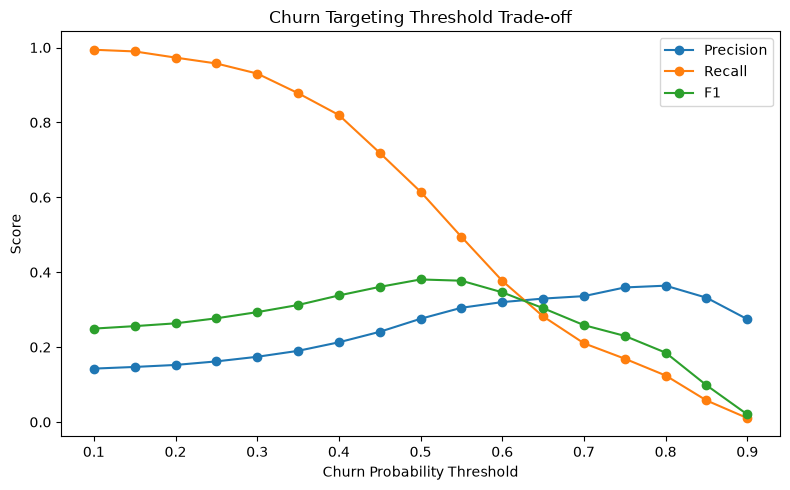

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_table['threshold'],
    threshold_table['precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_table['threshold'],
    threshold_table['recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_table['threshold'],
    threshold_table['f1'],
    marker='o',
    label='F1'
)

plt.xlabel(
    'Churn Probability Threshold'
)

plt.ylabel('Score')

plt.title(
    'Churn Targeting Threshold Trade-off'
)

plt.legend()

plt.tight_layout()

plt.savefig(
    '../outputs/figures/04_threshold_tradeoff.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

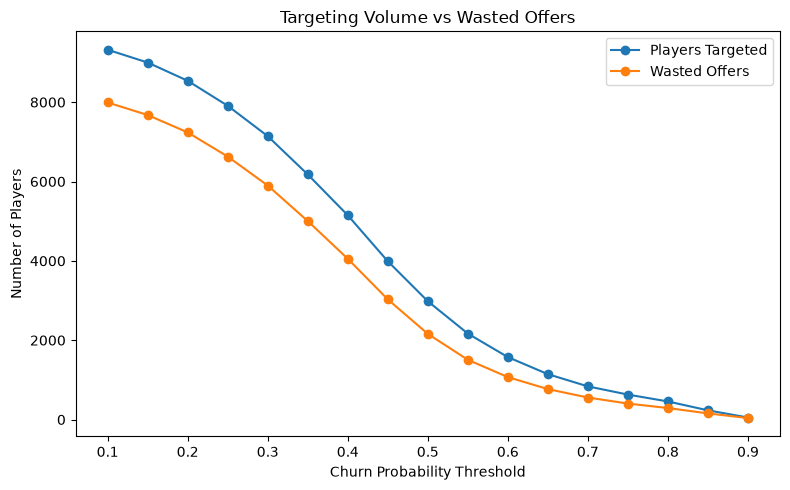

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_table['threshold'],
    threshold_table['targeted_players'],
    marker='o',
    label='Players Targeted'
)

plt.plot(
    threshold_table['threshold'],
    threshold_table['wasted_offers'],
    marker='o',
    label='Wasted Offers'
)

plt.xlabel(
    'Churn Probability Threshold'
)

plt.ylabel(
    'Number of Players'
)

plt.title(
    'Targeting Volume vs Wasted Offers'
)

plt.legend()

plt.tight_layout()

plt.savefig(
    '../outputs/figures/04_wasted_offers.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

## Business Threshold

The `0.50` threshold is used only as a provisional evaluation threshold, not as the economically optimal threshold.

A player should be targeted when:

**P(churn) × Intervention Uplift × Retained Player Value > Offer Cost**

Equivalently:

**P(churn) > Offer Cost / (Intervention Uplift × Retained Player Value)**

Because offer cost, intervention uplift, and retained-player value are not available in the supplied data, an economically optimal threshold cannot be estimated directly.

In [20]:
snapshot_summary.to_csv(
    '../outputs/tables/04_churn_snapshot_summary.csv',
    index=False
)

threshold_table.to_csv(
    '../outputs/tables/04_churn_thresholds.csv',
    index=False
)

coefficients.to_csv(
    '../outputs/tables/04_churn_coefficients.csv',
    index=False
)

test[
    [
        'device_id',
        'snapshot_date',
        'churn',
        'churn_probability',
        'predicted_churn'
    ]
].to_csv(
    '../outputs/tables/04_churn_test_predictions.csv',
    index=False
)

print(
    "Part 4 outputs saved successfully."
)

Part 4 outputs saved successfully.


## Final Findings

- The time-based test set contains **9,617 active players**, with an observed 14-day churn rate of **13.90%**.
- The logistic-regression model achieves a **ROC-AUC of 0.7334** and **PR-AUC of 0.2811**, compared with a churn prevalence of 0.1390.
- At the provisional **0.50 threshold**, the model targets **2,982 players** and identifies **822 of 1,337 churners**, corresponding to **61.48% recall** and **27.57% precision**.
- This threshold would also target **2,160 non-churners**, showing the trade-off between capturing churners and unnecessary retention offers.
- The 0.50 threshold is used only as a reference point. The economically optimal targeting threshold cannot be determined without intervention uplift, offer cost, and retained-player value.
- Model coefficients are interpreted as predictive associations rather than causal effects.